# 🎓 第3章 第2课：分组单调性与多空组合

**本节目标**：对每个因子做“分班考试”，看两件事：

1. **单调性**：组号越高，收益是否越高（或越低）？
2. **多空组合**：高组 − 低组的收益是否显著？

对应原书 3.2~3.8 节的因子实证框架。

In [1]:
import sys
from pathlib import Path

def _find_root():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / 'src' / 'factor_zero').exists():
            return p
    raise FileNotFoundError('找不到仓库根目录，请从仓库内启动 notebook')
ROOT = _find_root()
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from factor_zero.data import load_ashare_panel
from factor_zero.factors import build_factor_returns
from factor_zero.statistics import factor_summary, nw_t_stat
from factor_zero.sorting import long_short_factor, monotonicity_test

FACTOR_NAMES = ['MKT', 'SMB', 'HML', 'WML', 'RMW', 'CMA', 'TURN']
FACTOR_CN = {'MKT': '市场', 'SMB': '规模', 'HML': '价值',
             'WML': '动量', 'RMW': '盈利', 'CMA': '投资', 'TURN': '换手率'}

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Noto Sans CJK SC', 'DejaVu Sans']
print('✅ 环境就绪，开始学习！')

✅ 环境就绪，开始学习！


In [2]:
panel = load_ashare_panel()
ret = panel['ret']
specs = {
    'SMB': ('size', False),      # 小市值 − 大市值
    'HML': ('bm', True),         # 高BM − 低BM
    'WML': ('momentum', True),   # 高动量 − 低动量
    'RMW': ('roe', True),        # 高ROE − 低ROE
    'CMA': ('investment', False),# 低投资 − 高投资
    'TURN': ('turnover', False), # 低换手 − 高换手
}
ports, rows = {}, {}
for name, (key, high) in specs.items():
    f, port, groups = long_short_factor(panel[key], ret, n_groups=10, high_minus_low=high)
    ports[name] = port
    rho = monotonicity_test(port)['rho']
    s = factor_summary(f)
    rows[name] = {'Spearman rho': rho, '年化多空': s['mean_ann'], 'NW t': s['t_stat']}
table = pd.DataFrame(rows).T
table.round(4)

,Spearman rho,年化多空,NW t
SMB,-0.9273,0.2510,2.0356
HML,-0.9879,-0.2082,-2.1130
WML,0.8061,0.1957,1.4069
RMW,0.8303,0.1009,1.1690
CMA,-0.0545,0.0297,0.4578
TURN,0.0788,-0.0533,-0.4272


### 怎么读这张表？

- **rho ≈ +1**：组号越高收益越高（完美单调上升）；**rho ≈ −1**：完美单调下降；
- **年化多空**：按因子定义方向（见表）的多空组合年化收益；
- **NW t**：|t| > 2 才在 95% 置信下显著。

> 注意：**rho 的符号取决于排序变量的方向**。SMB 的排序变量是市值，rho 为负表示“市值越小、收益越高”，对应 SMB（小减大）为正；HML 同理。
> 示例面板是教学数据，符号和显著性只用于演示，不代表真实 A 股结论。

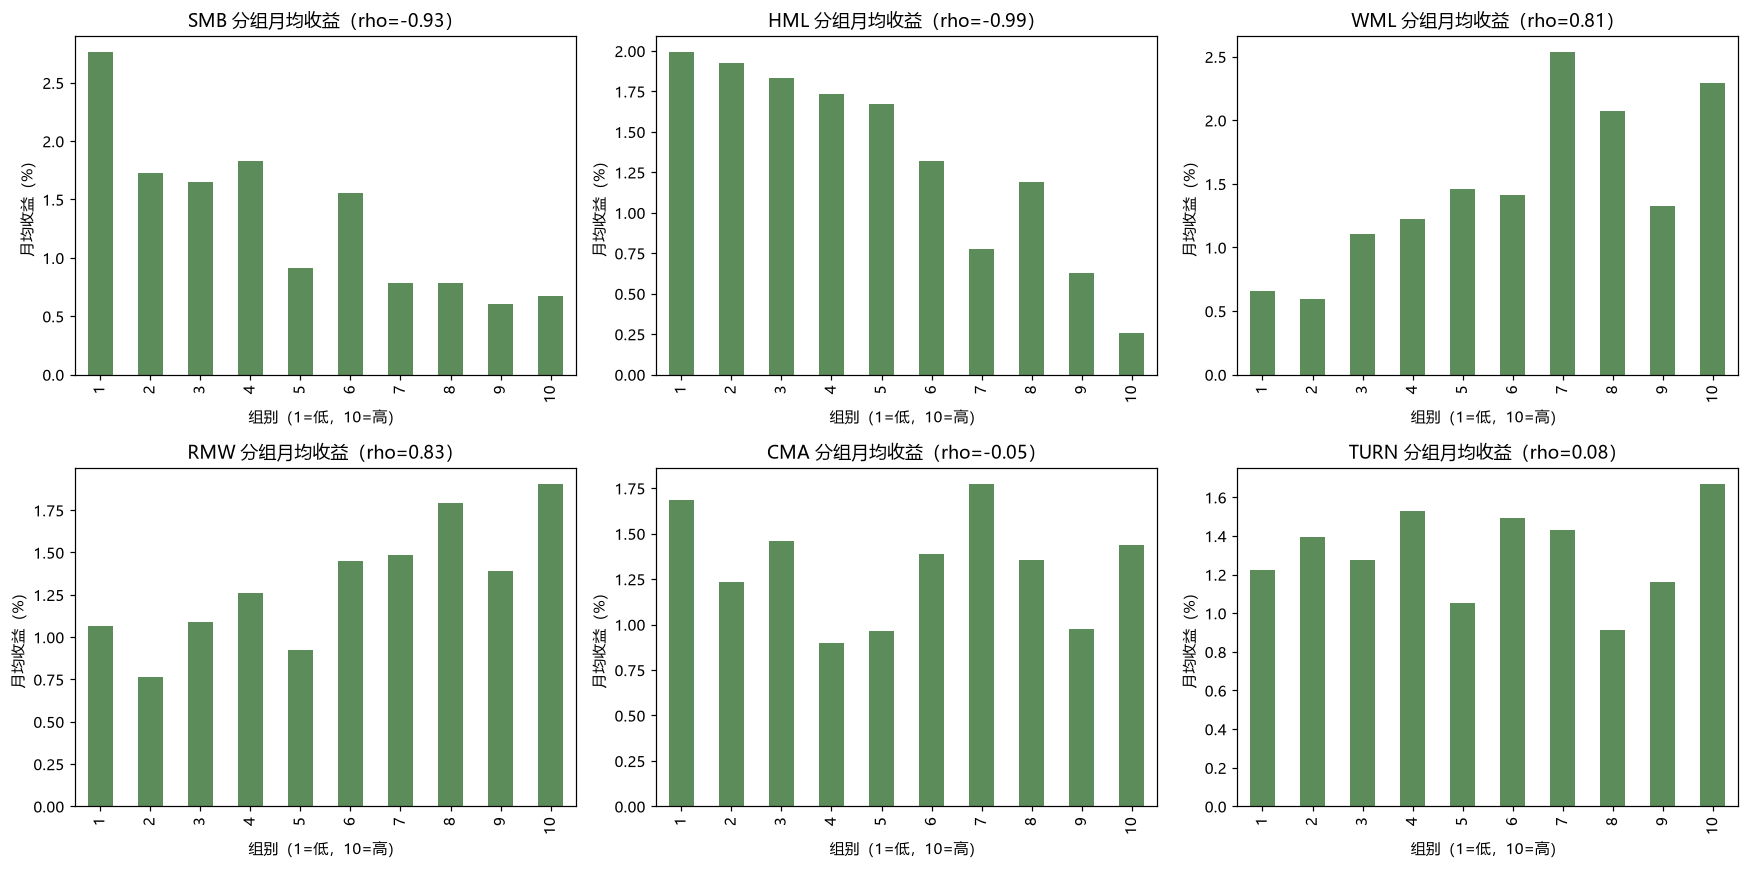

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, (name, port) in zip(axes.flat, ports.items()):
    means = port.mean() * 100
    means.plot(kind='bar', ax=ax, color='#5B8C5A')
    rho = table.loc[name, 'Spearman rho']
    ax.set_title(f'{name} 分组月均收益（rho={rho:.2f}）')
    ax.set_xlabel('组别（1=低，10=高）')
    ax.set_ylabel('月均收益（%）')
plt.tight_layout(); plt.show()

## 双重排序：控制市值后，价值因子还剩多少？

高 BM 组可能恰好全是小盘股。用**条件双重排序**：

1. 先按市值分 3 层；
2. 每层内部按 BM 分 5 组；
3. 在每层内算 BM 价差（组5 − 组1）。

如果在每一层内 BM 价差都还在，说明价值因子不是规模的“马甲”。

In [4]:
from factor_zero.sorting import quantile_group, sort_portfolios
common = ret.index.intersection(panel['bm'].index).intersection(panel['size'].index)
spreads = {1: [], 2: [], 3: []}
for t in range(len(common) - 1):
    d, dn = common[t], common[t + 1]
    sg = quantile_group(panel['size'].loc[d].dropna(), n_groups=3)
    for layer in [1, 2, 3]:
        inside = sg[sg == layer].index
        if len(inside) < 5:
            continue
        bm_in = panel['bm'].loc[d, inside].dropna()
        g = quantile_group(bm_in, n_groups=5)
        sub_ret = ret.loc[[dn], g.index]
        sub_g = g.to_frame().T.copy(); sub_g.index = [dn]
        port_s = sort_portfolios(sub_ret, sub_g, n_groups=5)
        spreads[layer].append(port_s.iloc[0, 4] - port_s.iloc[0, 0])

for layer in [1, 2, 3]:
    s = pd.Series(spreads[layer])
    t_nw, _ = nw_t_stat(s)
    print(f'市值第{layer}层（{"小" if layer==1 else "中" if layer==2 else "大"}）：'
          f'{s.mean()*100:+.3f}%/月，NW t={t_nw:.2f}，共{len(s)}期')

市值第1层（小）：-1.132%/月，NW t=-1.43，共82期
市值第2层（中）：-1.170%/月，NW t=-1.22，共82期
市值第3层（大）：-1.210%/月，NW t=-1.60，共82期


## ✋ 试一试

1. 把分组数从 10 改成 5，rho 和多空收益会怎么变？
2. 把 `TURN` 的方向反过来，rho 的符号怎么变？
3. 双重排序里把层数从 3 改成 5，每层的样本变少后结果还稳定吗？

## ✅ 本节小结

- 单调性看“组号—收益”的秩相关；多空组合看高组减低组；
- 方向由定义决定，符号要和经济学预期对照；
- 双重排序控制混淆因子（如市值），看增量解释力。

> 下一课：七大因子的绩效比较、相关性与分区间稳健性。